In [2]:
# 1. Kết nối Google Drive để lưu dữ liệu lâu dài (không mất khi Colab reset)
from google.colab import drive
drive.mount('/content/drive')

# 2. Tạo cấu trúc thư mục cố định theo blueprint mục 3
import os

BASE = '/content/drive/MyDrive/flower-multilabel-project'

classes = [
    'hoa_hong', 'hoa_huong_duong', 'hoa_cuc', 'hoa_tulip', 'hoa_bo_cong_anh',
    'hoa_sen', 'hoa_lan', 'hoa_mai', 'hoa_dao', 'hoa_oai_huong'
]

folders = [
    'notebooks',
    'data/raw',
    'data/composite/images',
    'data/augmented',
    'data/splits/train', 'data/splits/val', 'data/splits/test',
    'data/metadata',
    'models/checkpoints', 'models/final',
    'backend/static/uploads',
    'frontend',
    'docs',
    'reports/weekly_progress',
]

for f in folders:
    os.makedirs(os.path.join(BASE, f), exist_ok=True)

for c in classes:
    os.makedirs(os.path.join(BASE, 'data/raw', c), exist_ok=True)

print("Đã tạo xong cấu trúc thư mục!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã tạo xong cấu trúc thư mục!


In [3]:
# 1. Upload file kaggle.json
from google.colab import files
uploaded = files.upload()  # chọn file kaggle.json vừa tải

# 2. Cấu hình Kaggle API
import os
os.makedirs('/root/.kaggle', exist_ok=True)
os.system('cp kaggle.json /root/.kaggle/')
os.system('chmod 600 /root/.kaggle/kaggle.json')

# 3. Tải dataset "Flowers Recognition"
!pip install -q kaggle
!kaggle datasets download -d alxmamaev/flowers-recognition -p /content/flowers_temp --unzip

Saving kaggle.json to kaggle (1).json
Dataset URL: https://www.kaggle.com/datasets/alxmamaev/flowers-recognition
License(s): unknown
100% 225M/225M [00:01<00:00, 126MB/s]



In [4]:
import shutil, glob

BASE = '/content/drive/MyDrive/flower-multilabel-project'
SRC = '/content/flowers_temp/flowers'  # tùy cấu trúc unzip, kiểm tra lại bằng !ls

mapping = {
    'daisy': 'hoa_cuc',
    'dandelion': 'hoa_bo_cong_anh',
    'rose': 'hoa_hong',
    'sunflower': 'hoa_huong_duong',
    'tulip': 'hoa_tulip',
}

for en_name, vn_id in mapping.items():
    src_folder = os.path.join(SRC, en_name)
    dst_folder = os.path.join(BASE, 'data/raw', vn_id)
    files_list = glob.glob(os.path.join(src_folder, '*'))
    for i, fpath in enumerate(files_list):
        ext = os.path.splitext(fpath)[1]
        shutil.copy(fpath, os.path.join(dst_folder, f'{vn_id}_{i:04d}{ext}'))
    print(f'{vn_id}: đã copy {len(files_list)} ảnh')

hoa_cuc: đã copy 764 ảnh
hoa_bo_cong_anh: đã copy 1052 ảnh
hoa_hong: đã copy 784 ảnh
hoa_huong_duong: đã copy 733 ảnh
hoa_tulip: đã copy 984 ảnh


hoa_mai: tổng 159 ảnh, đã đổi tên chuẩn
hoa_dao: tổng 168 ảnh, đã đổi tên chuẩn


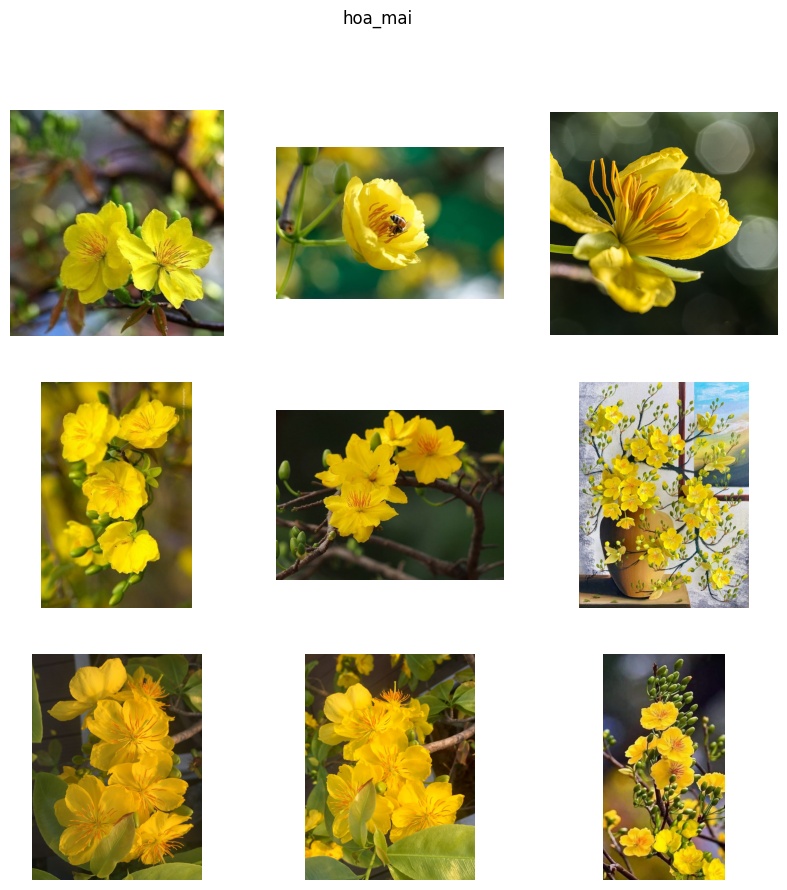

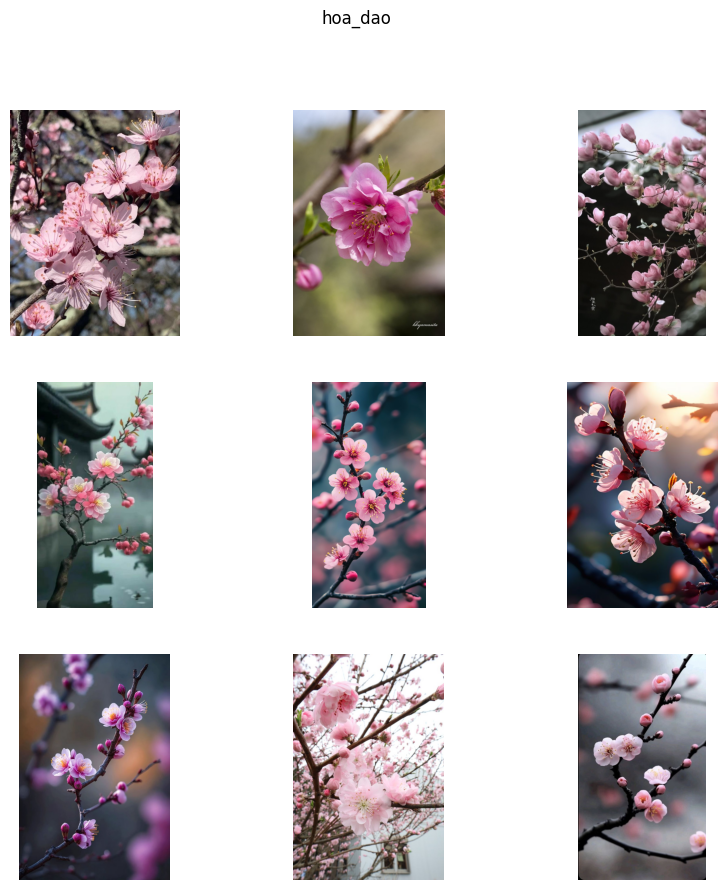

In [5]:
import os, glob
from PIL import Image
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/flower-multilabel-project'

def rename_and_count(class_id):
    folder = os.path.join(BASE, 'data/raw', class_id)
    files_list = sorted(glob.glob(os.path.join(folder, '*')))
    for i, fpath in enumerate(files_list):
        ext = os.path.splitext(fpath)[1].lower()
        new_name = os.path.join(folder, f'{class_id}_{i:04d}{ext}')
        if fpath != new_name:
            os.rename(fpath, new_name)
    print(f'{class_id}: tổng {len(files_list)} ảnh, đã đổi tên chuẩn')

rename_and_count('hoa_mai')
rename_and_count('hoa_dao')

# Preview lại để chắc chắn ảnh đúng
def preview(class_id, n=9):
    files_list = glob.glob(os.path.join(BASE, 'data/raw', class_id, '*'))[:n]
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    for ax, fpath in zip(axes.flat, files_list):
        img = Image.open(fpath)
        ax.imshow(img)
        ax.axis('off')
    plt.suptitle(class_id)
    plt.show()

preview('hoa_mai')
preview('hoa_dao')

In [6]:
!pip install -q tensorflow-datasets

import tensorflow_datasets as tfds

ds, info = tfds.load('oxford_flowers102', split='train+test+validation', with_info=True, as_supervised=False)
class_names = info.features['label'].names
print(class_names)  # kiểm tra để chắc đúng tên

['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold', 'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle', 'snapdragon', "colt's foot", 'king protea', 'spear thistle', 'yellow iris', 'globe-flower', 'purple coneflower', 'peruvian lily', 'balloon flower', 'giant white arum lily', 'fire lily', 'pincushion flower', 'fritillary', 'red ginger', 'grape hyacinth', 'corn poppy', 'prince of wales feathers', 'stemless gentian', 'artichoke', 'sweet william', 'carnation', 'garden phlox', 'love in the mist', 'mexican aster', 'alpine sea holly', 'ruby-lipped cattleya', 'cape flower', 'great masterwort', 'siam tulip', 'lenten rose', 'barbeton daisy', 'daffodil', 'sword lily', 'poinsettia', 'bolero deep blue', 'wallflower', 'marigold', 'buttercup', 'oxeye daisy', 'common dandelion', 'petunia', 'wild pansy', 'primula', 'sunflower', 'pelargonium', 'bishop of llandaff', 'gaura', 'geranium', 'orange dahlia', 'pink-yellow dahlia?', 'ca

In [7]:
target_map = {
    'lotus': 'hoa_sen',
    'hard-leaved pocket orchid': 'hoa_lan',
    'moon orchid': 'hoa_lan',
}

target_indices = {class_names.index(k): v for k, v in target_map.items()}
print(target_indices)

{77: 'hoa_sen', 1: 'hoa_lan', 6: 'hoa_lan'}


In [8]:
import os
from PIL import Image
import numpy as np

BASE = '/content/drive/MyDrive/flower-multilabel-project'
counters = {'hoa_sen': 0, 'hoa_lan': 0}

for example in ds:
    label_idx = int(example['label'].numpy())
    if label_idx in target_indices:
        class_id = target_indices[label_idx]
        img_array = example['image'].numpy()
        img = Image.fromarray(img_array)
        save_path = os.path.join(BASE, 'data/raw', class_id, f'{class_id}_{counters[class_id]:04d}.jpg')
        img.save(save_path)
        counters[class_id] += 1

print(counters)

{'hoa_sen': 137, 'hoa_lan': 100}


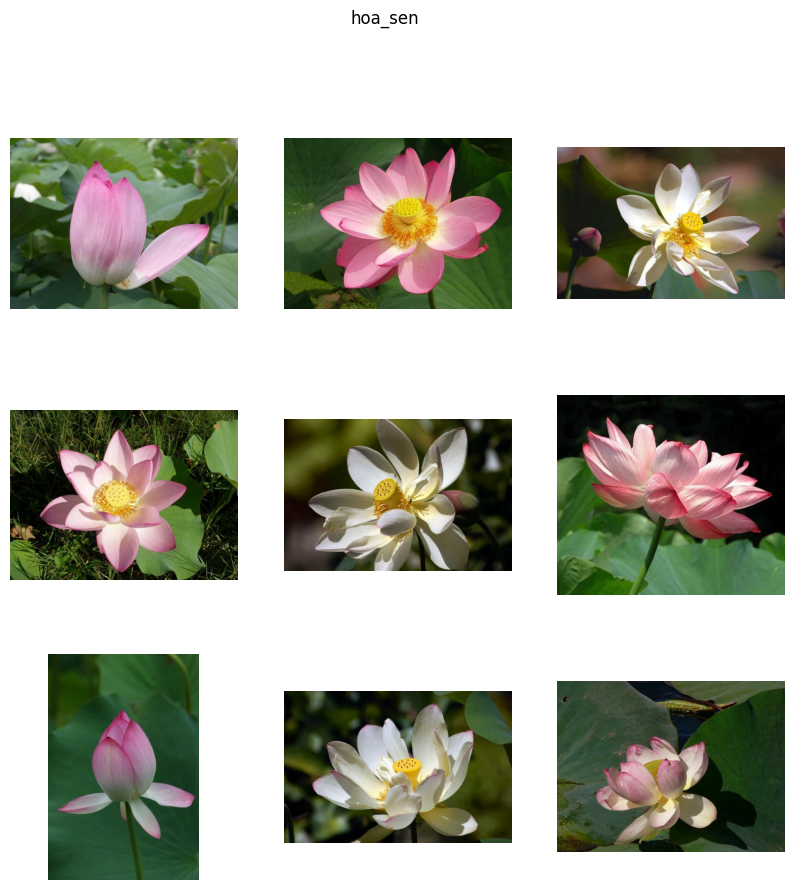

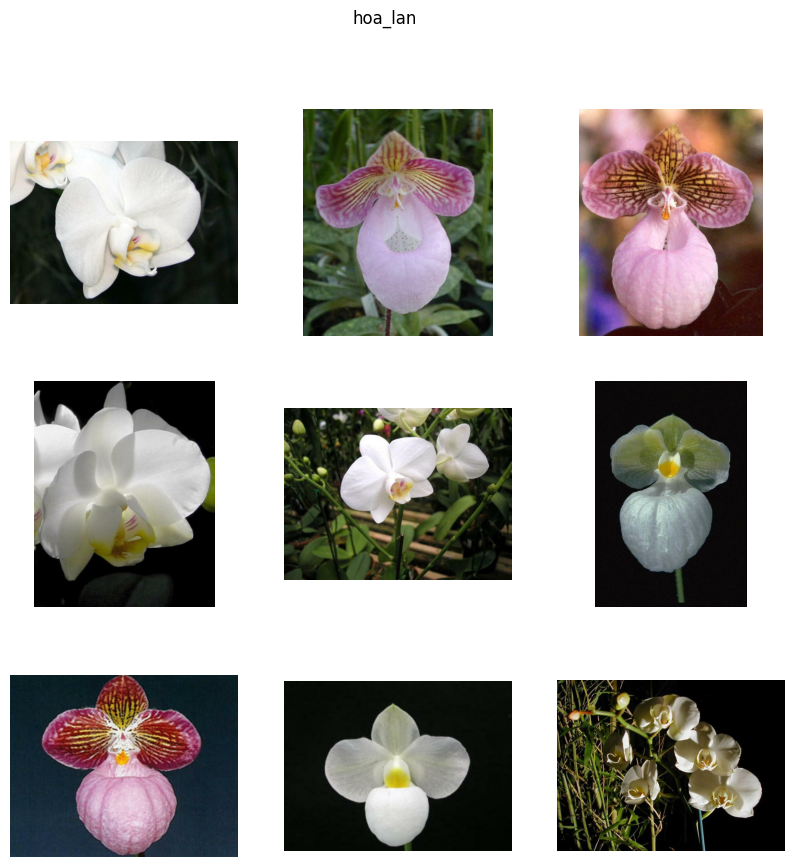

In [9]:
import matplotlib.pyplot as plt
import glob

def preview(class_id, n=9):
    files_list = glob.glob(os.path.join(BASE, 'data/raw', class_id, '*'))[:n]
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    for ax, fpath in zip(axes.flat, files_list):
        img = Image.open(fpath)
        ax.imshow(img)
        ax.axis('off')
    plt.suptitle(class_id)
    plt.show()

preview('hoa_sen')
preview('hoa_lan')